# Potato Disease Classification — Training & Experiment Tracking


## 1. Imports, GPU check, and reproducibility


In [1]:
import os, json, random, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import mlflow
import mlflow.tensorflow
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU devices:", gpus)
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


C:\Users\LENOVO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.20.0
GPU devices: []


## 2. Dataset paths and Potato only



In [2]:
# Project paths and configuration
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SOURCE_DATA_DIR = PROJECT_DIR / "dataset" / "Potato"  # original, unsplit Potato folders
SPLIT_DATA_DIR = PROJECT_DIR / "dataset" / "split"   # generated automatically below
TRAIN_DIR = SPLIT_DATA_DIR / "train"
VAL_DIR = SPLIT_DATA_DIR / "val"
TEST_DIR = SPLIT_DATA_DIR / "test"

POTATO_CLASSES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
]
IMAGE_SIZE = 256
BATCH_SIZE = 32
EPOCHS = 20
VALID_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Check that the original Potato-only folders exist.
if not SOURCE_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Potato dataset folder not found: {SOURCE_DATA_DIR}. "
        "Place the three Potato class folders inside dataset/Potato/"
    )
missing = [c for c in POTATO_CLASSES if not (SOURCE_DATA_DIR / c).is_dir()]
if missing:
    raise FileNotFoundError(f"Missing Potato class folders in {SOURCE_DATA_DIR}: {missing}")

# Create a reproducible, stratified 70/15/15 split from the source folders.
# If split folders already exist, they are reused. Delete dataset/split to regenerate them.
from sklearn.model_selection import train_test_split

split_is_ready = all(
    (split_dir / class_name).is_dir()
    for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]
    for class_name in POTATO_CLASSES
)

if not split_is_ready:
    if SPLIT_DATA_DIR.exists():
        shutil.rmtree(SPLIT_DATA_DIR)
    for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
        for class_name in POTATO_CLASSES:
            (split_dir / class_name).mkdir(parents=True, exist_ok=True)

    for class_name in POTATO_CLASSES:
        class_source = SOURCE_DATA_DIR / class_name
        image_files = sorted(
            p for p in class_source.iterdir()
            if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS
        )
        if len(image_files) < 3:
            raise ValueError(f"Class {class_name} has too few images to split: {len(image_files)}")

        train_files, remaining_files = train_test_split(
            image_files, test_size=0.30, random_state=SEED
        )
        val_files, test_files = train_test_split(
            remaining_files, test_size=0.50, random_state=SEED
        )

        for split_dir, split_files in [
            (TRAIN_DIR, train_files), (VAL_DIR, val_files), (TEST_DIR, test_files)
        ]:
            for image_path in split_files:
                shutil.copy2(image_path, split_dir / class_name / image_path.name)

print("Project:", PROJECT_DIR)
print("Original Potato dataset:", SOURCE_DATA_DIR)
print("Generated splits:", SPLIT_DATA_DIR)
print("Classes:", POTATO_CLASSES)
print("Split ratios: approximately 70% train / 15% validation / 15% test")


Project: d:\courses\Samsung Intern\FInal Project\plant idea\PlantCare_Potato_Project
Original Potato dataset: d:\courses\Samsung Intern\FInal Project\plant idea\PlantCare_Potato_Project\dataset\Potato
Generated splits: d:\courses\Samsung Intern\FInal Project\plant idea\PlantCare_Potato_Project\dataset\split
Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Split ratios: approximately 70% train / 15% validation / 15% test


## 3. EDA — image counts and class distribution

We count files in each split/class and visualize the distribution. This helps spot imbalance and missing classes before training.

,split,class,count
0,train,Potato___Early_blight,700
1,train,Potato___Late_blight,700
2,train,Potato___healthy,106
3,val,Potato___Early_blight,150
4,val,Potato___Late_blight,150
5,val,Potato___healthy,23
6,test,Potato___Early_blight,150
7,test,Potato___Late_blight,150
8,test,Potato___healthy,23


split,test,train,val
class,,,
Potato___Early_blight,150,700,150
Potato___Late_blight,150,700,150
Potato___healthy,23,106,23


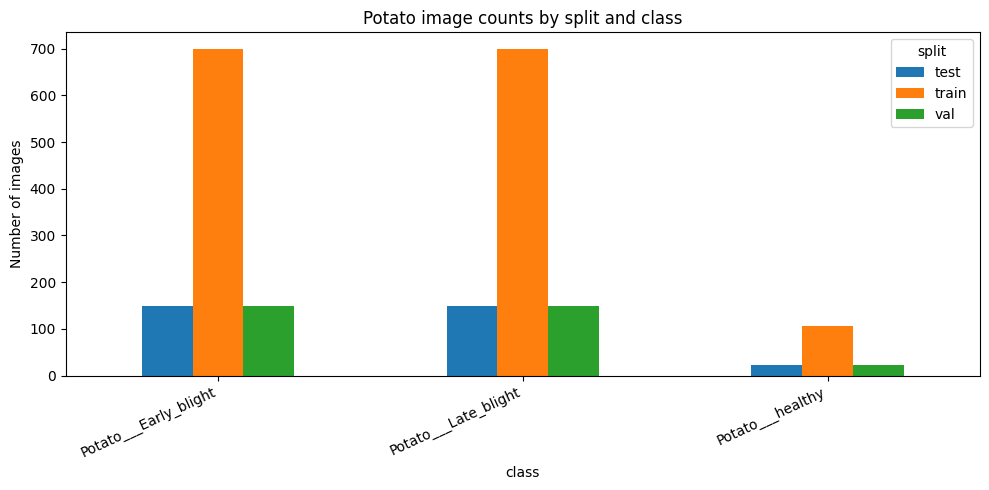

In [3]:
def count_images(folder):
    rows = []
    for class_name in POTATO_CLASSES:
        class_dir = folder / class_name
        count = sum(
            1 for p in class_dir.iterdir()
            if p.is_file() and p.suffix.lower() in VALID_IMAGE_EXTENSIONS
        )
        rows.append({"split": folder.name, "class": class_name, "count": count})
    return rows

counts = pd.DataFrame(
    count_images(TRAIN_DIR) + count_images(VAL_DIR) + count_images(TEST_DIR)
)
display(counts)
display(counts.pivot(index="class", columns="split", values="count").fillna(0))

counts.pivot(index="class", columns="split", values="count").plot(kind="bar", figsize=(10,5))
plt.title("Potato image counts by split and class")
plt.ylabel("Number of images")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 4. View sample images


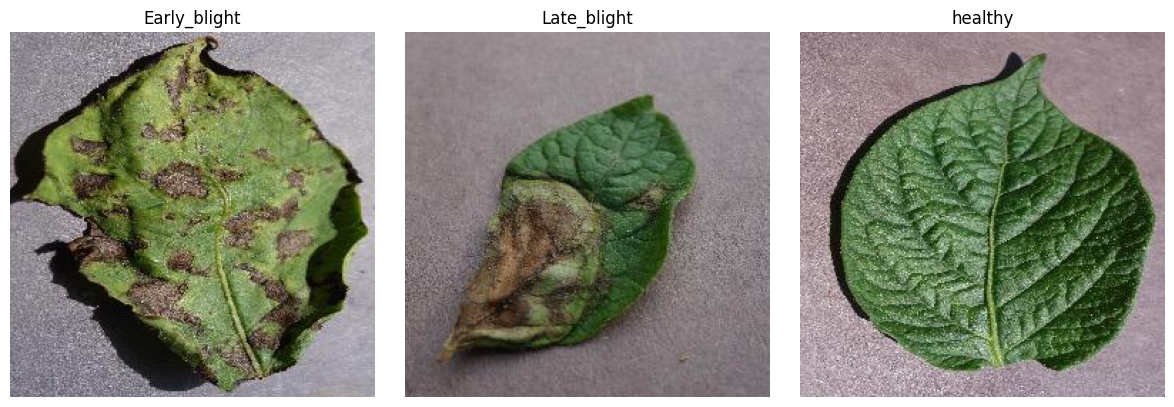

In [4]:
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(12,4))
for ax, class_name in zip(axes, POTATO_CLASSES):
    candidates = list((TRAIN_DIR/class_name).glob("*"))
    candidates = [p for p in candidates if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}]
    if candidates:
        img = Image.open(candidates[0]).convert("RGB")
        ax.imshow(img)
        ax.set_title(class_name.replace("Potato___",""))
    ax.axis("off")
plt.tight_layout()
plt.show()


## 5. Data generators and preprocessing

Training images receive light augmentation. Validation and test data are not augmented. Images are loaded as RGB at 256×256. The CNN and MobileNetV2 preprocessing are included inside their respective models; EfficientNetB0 expects pixel values in the 0–255 range.

In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rotation_range=10,
    horizontal_flip=True,
    zoom_range=0.1
)
eval_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, classes=POTATO_CLASSES, target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE, class_mode="sparse", shuffle=True, seed=SEED
)
validation_generator = eval_datagen.flow_from_directory(
    VAL_DIR, classes=POTATO_CLASSES, target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE, class_mode="sparse", shuffle=False
)
test_generator = eval_datagen.flow_from_directory(
    TEST_DIR, classes=POTATO_CLASSES, target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE, class_mode="sparse", shuffle=False
)

class_names = train_generator.class_indices
print("Class mapping:", class_names)


Found 1506 images belonging to 3 classes.
Found 323 images belonging to 3 classes.
Found 323 images belonging to 3 classes.
Class mapping: {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}


## 6. MLflow setup



In [7]:
import mlflow
from pathlib import Path

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

MLFLOW_DB = PROJECT_DIR / "mlflow.db"

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")
mlflow.set_experiment("PlantCare-Potato-Disease")

RUNS = []

2026/10/27 18:44:36 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 18:44:37 INFO mlflow.store.db.utils: Updating database tables
2026/10/27 18:45:01 INFO mlflow.tracking.fluent: Experiment with name 'PlantCare-Potato-Disease' does not exist. Creating a new experiment.


## 7. Model 1 — CNN 

This keeps the original CNN-style architecture and Adam + SparseCategoricalCrossentropy training setup. A Rescaling layer is added so the model itself receives normalized pixel values consistently in both notebook and API.

In [8]:
def build_custom_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
        tf.keras.layers.Rescaling(1./255),
        tf.keras.layers.Conv2D(32, (3,3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
        tf.keras.layers.MaxPooling2D((2,2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(len(POTATO_CLASSES), activation="softmax")
    ], name="custom_cnn")
    model.compile(optimizer="adam",
                 loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                 metrics=["accuracy"])
    return model

def train_and_log(model_name, model, epochs=EPOCHS):
    run_start = time.time()
    with mlflow.start_run(run_name=model_name) as run:
        mlflow.log_params({
            "model_name": model_name,
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "epochs": epochs,
            "classes": ",".join(POTATO_CLASSES),
            "optimizer": "adam",
            "dataset_scope": "Potato only"
        })
        callbacks = [
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6)
        ]
        history = model.fit(
            train_generator,
            validation_data=validation_generator,
            epochs=epochs,
            callbacks=callbacks,
            verbose=1
        )
        val_loss, val_acc = model.evaluate(validation_generator, verbose=0)
        mlflow.log_metrics({
            "val_loss": float(val_loss),
            "val_accuracy": float(val_acc),
            "training_seconds": float(time.time()-run_start),
            "epochs_completed": len(history.history["loss"])
        })
        mlflow.log_dict(history.history, "training_history.json")
        mlflow.tensorflow.log_model(model, artifact_path="model")
        RUNS.append({"name": model_name, "model": model, "history": history,
                     "run_id": run.info.run_id, "val_accuracy": float(val_acc)})
    return model, history

cnn_model = build_custom_cnn()
cnn_model.summary()


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
cnn_model, cnn_history = train_and_log("Custom_CNN", cnn_model)


Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.5345 - loss: 0.8879 - val_accuracy: 0.6563 - val_loss: 0.7930 - learning_rate: 0.0010
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.7112 - loss: 0.6575 - val_accuracy: 0.7214 - val_loss: 0.6063 - learning_rate: 0.0010
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8413 - loss: 0.4003 - val_accuracy: 0.8545 - val_loss: 0.3898 - learning_rate: 0.0010
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8260 - loss: 0.4162 - val_accuracy: 0.8142 - val_loss: 0.4445 - learning_rate: 0.0010
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.8479 - loss: 0.3661 - val_accuracy: 0.8916 - val_loss: 0.2978 - learning_rate: 0.0010
Epoch 6/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8891 - loss: 0.2596 - val_accuracy: 0.9288 - val_loss: 0.2124 - learning_rate: 0.0010
Epoch 7/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.8865 - loss: 0.2745 - val_accuracy: 

2026/10/27 19:04:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 19:04:28 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


## 8. Model 2 — MobileNetV2 (Transfer Learning)



In [10]:
def build_mobilenetv2():
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False,
        weights="imagenet"
    )
    base.trainable = False
    inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(inputs) # MobileNetV2 preprocessing
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(len(POTATO_CLASSES), activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

mobilenet_model = build_mobilenetv2()
mobilenet_model.summary()


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_30948\742267610.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 8, 8, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
mobilenet_model, mobilenet_history = train_and_log("MobileNetV2", mobilenet_model)


Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8147 - loss: 0.4971 - val_accuracy: 0.9350 - val_loss: 0.2146 - learning_rate: 0.0010
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9363 - loss: 0.1981 - val_accuracy: 0.9474 - val_loss: 0.1576 - learning_rate: 0.0010
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 47s 985ms/step - accuracy: 0.9535 - loss: 0.1459 - val_accuracy: 0.9628 - val_loss: 0.1137 - learning_rate: 0.0010
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 47s 983ms/step - accuracy: 0.9675 - loss: 0.1144 - val_accuracy: 0.9690 - val_loss: 0.0974 - learning_rate: 0.0010
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 47s 981ms/step - accuracy: 0.9668 - loss: 0.1008 - val_accuracy: 0.9690 - val_loss: 0.0923 - learning_rate: 0.0010
Epoch 6/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 48s 988ms/step - accuracy: 0.9714 - loss: 0.0880 - val_accuracy: 0.9752 - val_loss: 0.0783 - learning_rate: 0.0010
Epoch 7/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 47s 986ms/step - accuracy: 0.9748 - loss: 0.0843 -

2026/10/27 19:25:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 19:25:42 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


## 9. Model 3 — EfficientNetB0 (Transfer Learning)

EfficientNetB0 provides a second modern pretrained architecture for comparison. Its preprocessing is built into the Keras application model, so inputs remain RGB pixel values in the 0–255 range.

In [12]:
def build_efficientnetb0():
    base = tf.keras.applications.EfficientNetB0(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False,
        weights="imagenet"
    )
    base.trainable = False
    inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(len(POTATO_CLASSES), activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name="efficientnetb0_transfer")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

efficientnet_model = build_efficientnetb0()
efficientnet_model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step


Model: "efficientnetb0_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [13]:
efficientnet_model, efficientnet_history = train_and_log("EfficientNetB0", efficientnet_model)


Epoch 1/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.8187 - loss: 0.5424 - val_accuracy: 0.8978 - val_loss: 0.3142 - learning_rate: 0.0010
Epoch 2/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.9356 - loss: 0.2480 - val_accuracy: 0.9381 - val_loss: 0.1979 - learning_rate: 0.0010
Epoch 3/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.9595 - loss: 0.1711 - val_accuracy: 0.9567 - val_loss: 0.1484 - learning_rate: 0.0010
Epoch 4/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.9661 - loss: 0.1387 - val_accuracy: 0.9690 - val_loss: 0.1167 - learning_rate: 0.0010
Epoch 5/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.9741 - loss: 0.1133 - val_accuracy: 0.9845 - val_loss: 0.0970 - learning_rate: 0.0010
Epoch 6/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.9794 - loss: 0.0942 - val_accuracy: 0.9845 - val_loss: 0.0891 - learning_rate: 0.0010
Epoch 7/20
48/48 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.9841 - loss: 0.0797 - val_accuracy: 

2026/10/27 19:48:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 19:48:20 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


## 10. Compare training curves and validation scores


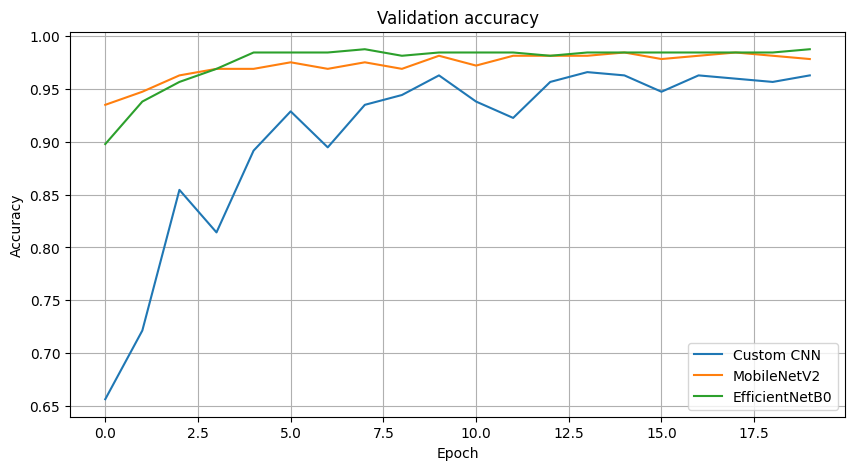

Selected by validation accuracy: EfficientNetB0 0.9876161217689514


In [14]:
histories = {
    "Custom CNN": cnn_history,
    "MobileNetV2": mobilenet_history,
    "EfficientNetB0": efficientnet_history
}
plt.figure(figsize=(10,5))
for name, hist in histories.items():
    plt.plot(hist.history["val_accuracy"], label=name)
plt.title("Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

best_run = max(RUNS, key=lambda x: x["val_accuracy"])
best_model = best_run["model"]
best_name = best_run["name"]
print("Selected by validation accuracy:", best_name, best_run["val_accuracy"])


## 11. Final evaluation on the test set

We evaluate the selected model once on the test set and report precision, recall, F1-score, and confusion matrix. The test generator is not shuffled so predictions align with labels.

11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 775ms/step - accuracy: 1.0000 - loss: 0.0272
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 999ms/step
Test loss: 0.02715482749044895
Test accuracy: 1.0
                       precision    recall  f1-score   support

Potato___Early_blight     1.0000    1.0000    1.0000       150
 Potato___Late_blight     1.0000    1.0000    1.0000       150
     Potato___healthy     1.0000    1.0000    1.0000        23

             accuracy                         1.0000       323
            macro avg     1.0000    1.0000    1.0000       323
         weighted avg     1.0000    1.0000    1.0000       323



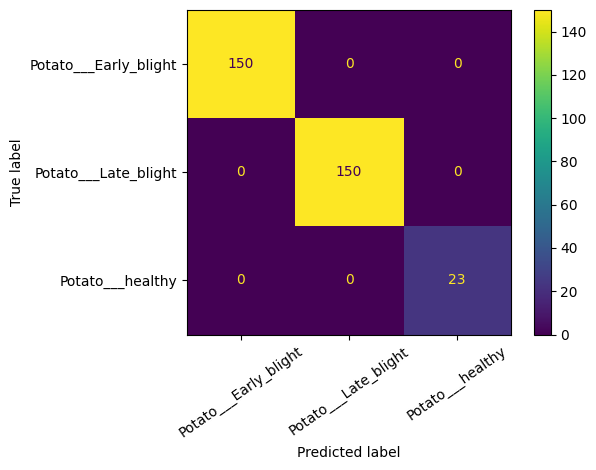

In [15]:
test_generator.reset()
test_loss, test_acc = best_model.evaluate(test_generator, verbose=1)
test_generator.reset()
y_prob = best_model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_generator.classes

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)
print(classification_report(y_true, y_pred, target_names=POTATO_CLASSES, digits=4))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=POTATO_CLASSES)
disp.plot(xticks_rotation=35)
plt.tight_layout()
plt.show()


## 12. Sample predictions

Display a few test images with the actual class, predicted class, and confidence.

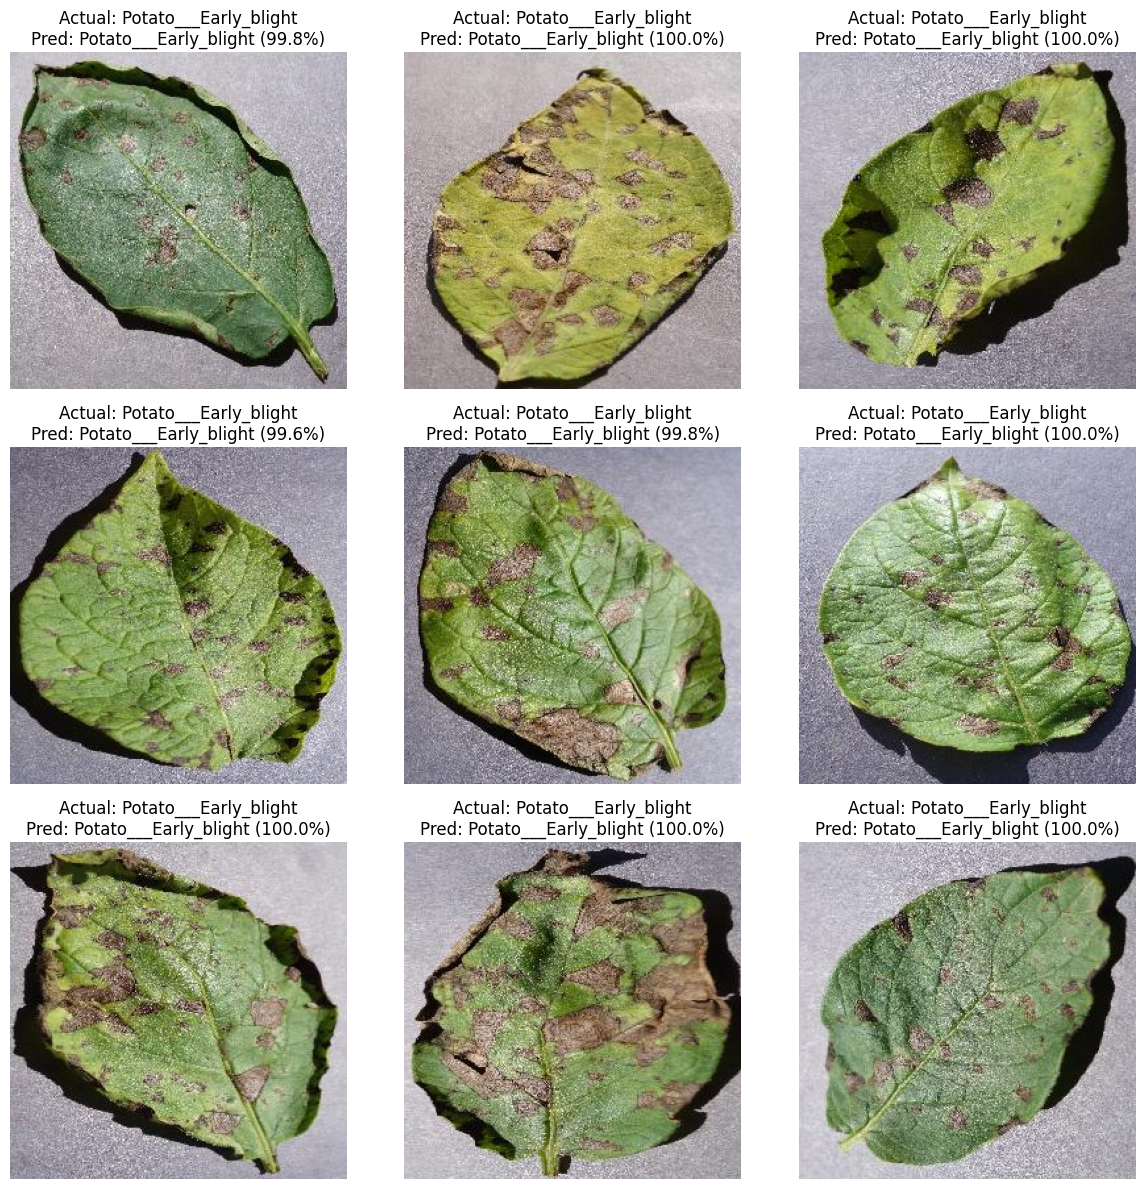

In [16]:
test_generator.reset()
images, labels = next(test_generator)
predictions = best_model.predict(images, verbose=0)
predicted_ids = np.argmax(predictions, axis=1)

fig, axes = plt.subplots(3, 3, figsize=(12,12))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].astype("uint8"))
    ax.set_title(
        f"Actual: {POTATO_CLASSES[int(labels[i])] }\n"
        f"Pred: {POTATO_CLASSES[int(predicted_ids[i])] } "
        f"({predictions[i][predicted_ids[i]]*100:.1f}%)"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()


## 13. Save the selected model and class labels for FastAPI



In [17]:
MODEL_DIR = PROJECT_DIR / "backend" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
best_model.save(MODEL_DIR / "plant_model.keras")

with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(POTATO_CLASSES, f, ensure_ascii=False, indent=2)

with mlflow.start_run(run_name="Selected_Model_Test_Evaluation"):
    mlflow.log_param("selected_model", best_name)
    mlflow.log_metric("test_accuracy", float(test_acc))
    mlflow.log_metric("test_loss", float(test_loss))
    mlflow.log_dict(classification_report(y_true, y_pred, target_names=POTATO_CLASSES, output_dict=True),
                    "test_classification_report.json")

print("Exported:", MODEL_DIR / "plant_model.keras")
print("Class names:", MODEL_DIR / "class_names.json")


Exported: d:\courses\Samsung Intern\FInal Project\plant idea\PlantCare_Potato_Project\backend\models\plant_model.keras
Class names: d:\courses\Samsung Intern\FInal Project\plant idea\PlantCare_Potato_Project\backend\models\class_names.json
